In [170]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [171]:
TICKER = "BNB-USD"
LOOKBACK = 60
H = 1

DATASET_DIR = "../data/processed/lstm_close_L60_start2017-11-09"
NPZ_PATH = os.path.join(DATASET_DIR, f"{TICKER}_Close_L{LOOKBACK}_H{H}.npz")

MODELS_DIR = "../models/attention_lstm"
os.makedirs(MODELS_DIR, exist_ok=True)

FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

In [172]:
d = np.load(NPZ_PATH, allow_pickle=True)

X_train = d["X_train"]
y_train = d["y_train"]

X_val = d["X_val"]
y_val = d["y_val"]

X_test = d["X_test"]
y_test = d["y_test"]

scaler_mean = d["scaler_mean"]
scaler_scale = d["scaler_scale"]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)
print("scaler_mean:", scaler_mean, "scaler_scale:", scaler_scale)

X_train: (2031, 60, 1) y_train: (2031,)
X_val  : (435, 60, 1) y_val  : (435,)
X_test : (436, 60, 1) y_test : (436,)
scaler_mean: [162.61605054] scaler_scale: [180.38970608]


In [173]:
# scale y (target Close) - FIT hanya di y_train
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train.reshape(-1,1)).ravel()
y_val_s   = y_scaler.transform(y_val.reshape(-1,1)).ravel()
y_test_s  = y_scaler.transform(y_test.reshape(-1,1)).ravel()

In [174]:
def rmse(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))

def mae(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return float(np.mean(np.abs(y_pred - y_true)))

def mape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return float(np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100.0)

In [175]:
class AdditiveAttention(layers.Layer):
    def __init__(self, attn_units=64, **kwargs):
        super().__init__(**kwargs)
        self.attn_units = attn_units
        self.W1 = layers.Dense(attn_units)
        self.V  = layers.Dense(1)

    def build(self, input_shape):
        # input_shape: (batch, timesteps, hidden_dim)
        self.W1.build(input_shape)
        self.V.build((input_shape[0], input_shape[1], self.attn_units))
        super().build(input_shape)

    def call(self, values):
        score = self.V(tf.nn.tanh(self.W1(values)))
        weights = tf.nn.softmax(score, axis=1)
        context = tf.reduce_sum(weights * values, axis=1)
        return context, weights

    def get_config(self):
        config = super().get_config()
        config.update({"attn_units": self.attn_units})
        return config

In [176]:
def build_attention_lstm(input_shape, lstm_units=96, attn_units=128, dropout=0.2, lr=1e-3):
    inp = layers.Input(shape=input_shape)  # (lookback, n_features)

    x = layers.LSTM(lstm_units, return_sequences=True)(inp)
    x = layers.Dropout(dropout)(x)

    context, weights = AdditiveAttention(attn_units=attn_units)(x)

    x = layers.Dense(32, activation="relu")(context)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="linear")(x)

    model = Model(inputs=inp, outputs=out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="mse"
    )
    return model

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
np.random.seed(SEED)

model = build_attention_lstm(
    input_shape=X_train.shape[1:],
    lstm_units=96,
    attn_units=128,
    dropout=0.2,
    lr=1e-3
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 96)         │        37,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ additive_attention              │ [(None, 96), (None,    │        12,545 │
│ (AdditiveAttention)             │ 60, 1)]                │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,314 (208.26 KB)

 Trainable params: 53,314 (208.26 KB)

 Non-trainable params: 0 (0.00 B)

In [177]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-6),
]

history = model.fit(
    X_train, y_train_s,
    validation_data=(X_val, y_val_s),
    epochs=200,
    batch_size=64,
    callbacks=callbacks,
    shuffle=False,
    verbose=1
)

Epoch 1/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.6389 - val_loss: 0.1877 - learning_rate: 0.0010
Epoch 2/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1560 - val_loss: 0.6877 - learning_rate: 0.0010
Epoch 3/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.2129 - val_loss: 0.1837 - learning_rate: 0.0010
Epoch 4/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1374 - val_loss: 0.1138 - learning_rate: 0.0010
Epoch 5/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0987 - val_loss: 0.2703 - learning_rate: 0.0010
Epoch 6/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1208 - val_loss: 0.1402 - learning_rate: 0.0010
Epoch 7/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.1103 - val_loss: 0.2024 - learning_rate: 0.0010
Epoch 8/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1065 - val_loss: 0.1853 - learning_rate: 0.0010
Epoch 9/200
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1055 - val_loss: 0.1495 - learning_rate: 0.0010
Epoch 10/2

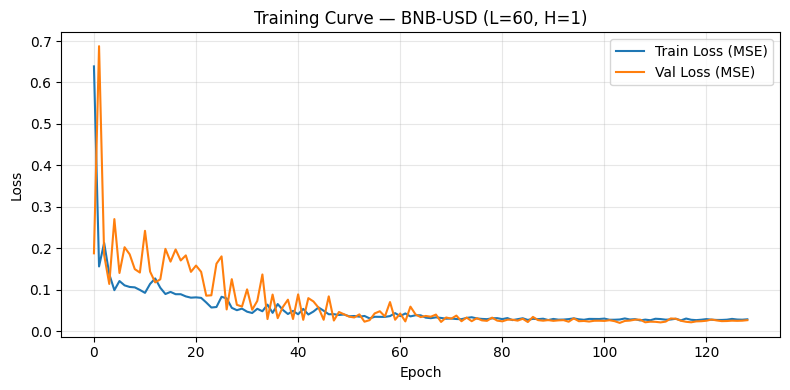

Best val_loss: 0.01978318579494953
Epoch best val_loss: 104


In [178]:
plt.figure(figsize=(8,4))
plt.plot(history.history["loss"], label="Train Loss (MSE)")
plt.plot(history.history["val_loss"], label="Val Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Training Curve — {TICKER} (L={LOOKBACK}, H={H})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Best val_loss:", float(np.min(history.history["val_loss"])))
print("Epoch best val_loss:", int(np.argmin(history.history["val_loss"]) + 1))

In [179]:
y_pred_s = model.predict(X_test, verbose=0).ravel()

# inverse scaling ke harga asli
y_pred = y_scaler.inverse_transform(y_pred_s.reshape(-1,1)).ravel()

In [180]:
metrics = {
    "ticker": TICKER,
    "lookback": LOOKBACK,
    "horizon": H,
    "test_RMSE": rmse(y_test, y_pred),
    "test_MAE": mae(y_test, y_pred),
    "test_MAPE": mape(y_test, y_pred),
}
metrics

{'ticker': 'BNB-USD',
 'lookback': 60,
 'horizon': 1,
 'test_RMSE': 69.83781857680302,
 'test_MAE': 49.020988254372135,
 'test_MAPE': 5.90358759143448}

In [181]:
# Baseline naive: prediksi hari ini = aktual hari sebelumnya (dalam test set)
yhat_naive = np.r_[y_test[0], y_test[:-1]]

print("Shapes:", y_test.shape, yhat_naive.shape)
print("First 5 y_test     :", y_test[:5])
print("First 5 yhat_naive :", yhat_naive[:5])  # harus sama dengan [y_test[0], y_test[0], y_test[1], ...]

print("NAIVE MAPE:", mape(y_test, yhat_naive))
print("NAIVE MAE :", mae(y_test, yhat_naive))
print("NAIVE RMSE:", rmse(y_test, yhat_naive))

Shapes: (436,) (436,)
First 5 y_test     : [570.27716064 562.72576904 572.85723877 576.44976807 571.82171631]
First 5 yhat_naive : [570.27716064 570.27716064 562.72576904 572.85723877 576.44976807]
NAIVE MAPE: 1.9464493011423416
NAIVE MAE : 15.224133272783472
NAIVE RMSE: 23.824438421680306


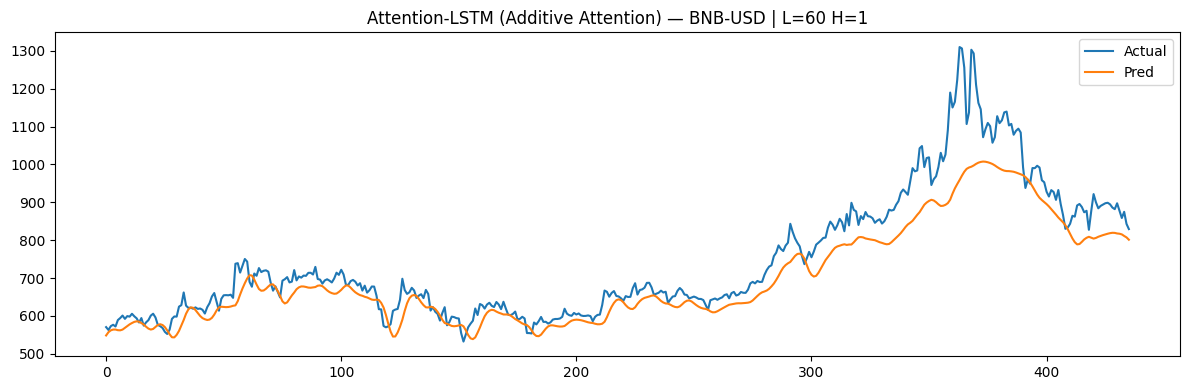

In [182]:
plt.figure(figsize=(12,4))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Pred")
plt.title(f"Attention-LSTM (Additive Attention) — {TICKER} | L={LOOKBACK} H={H}")
plt.legend()
plt.tight_layout()
plt.show()

In [183]:
# Save metrics
metrics_path = os.path.join(MODELS_DIR, f"metrics_{TICKER}_Close_L{LOOKBACK}_H{H}.csv")
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)
print("Saved metrics:", metrics_path)

# Save model
model_path = os.path.join(MODELS_DIR, f"attention_lstm_{TICKER}_Close_L{LOOKBACK}_H{H}.keras")
model.save(model_path)
print("Saved model:", model_path)

Saved metrics: ../models/attention_lstm\metrics_BNB-USD_Close_L60_H1.csv
Saved model: ../models/attention_lstm\attention_lstm_BNB-USD_Close_L60_H1.keras
